# Mixture of Truncated Parabolas: Data Generation and Gradient-Based Fitting

We consider a $K$-component mixture of univariate truncated-parabola densities:

$$
p_\theta(t)=\sum_{k=1}^K \pi_k\left[-\tau_k-\frac{(t-\mu_k)^2}{2\sigma_k^2}\right]_+,
\quad
\tau_k=-\frac12\left(\frac{3}{2\sigma_k}\right)^{2/3},
\quad
\pi_k\ge 0,
\quad
\sum_{k=1}^K \pi_k=1.
$$

For a scalar density, the Fenchel-Young objective is

$$
\ell(t_0;\theta)=\frac12 + \frac12\int p_\theta(u)^2\,du - p_\theta(t_0).
$$

For $K=1$ this reduces to the same closed-form FY loss used in the single-component notebook. For $K>1$, the squared-norm term contains overlap terms between components, so we evaluate $\int p_\theta(u)^2\,du$ numerically on a dense one-dimensional grid.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

np.random.seed(7)
torch.manual_seed(7)


In [2]:
def tau_from_sigma(sigma):
    return -0.5 * (3.0 / (2.0 * sigma)) ** (2.0 / 3.0)


def density_truncated_parabola(t, mu, sigma):
    tau = tau_from_sigma(sigma)
    return np.maximum(-tau - (t - mu) ** 2 / (2.0 * sigma ** 2), 0.0)


def mixture_density_truncated_parabola(t, mu, sigma, pi):
    out = np.zeros_like(np.asarray(t, dtype=np.float64), dtype=np.float64)
    for weight, mu_k, sigma_k in zip(pi, mu, sigma):
        out += weight * density_truncated_parabola(t, mu_k, sigma_k)
    return out


def support_radius(sigma):
    a = -tau_from_sigma(sigma)
    return np.sqrt(2.0 * sigma ** 2 * a)


def sample_truncated_parabola(mu, sigma, n, batch_size=4096):
    a = -tau_from_sigma(sigma)
    r = support_radius(sigma)

    out = []
    while len(out) < n:
        x = np.random.uniform(mu - r, mu + r, size=batch_size)
        y = np.random.uniform(0.0, a, size=batch_size)
        fx = density_truncated_parabola(x, mu, sigma)
        accepted = x[y <= fx]
        out.extend(accepted.tolist())
    return np.array(out[:n], dtype=np.float64)


def sample_mixture_truncated_parabola(mu, sigma, pi, n):
    labels = np.random.choice(len(pi), size=n, p=pi)
    samples = np.empty(n, dtype=np.float64)
    for k in range(len(pi)):
        idx = np.where(labels == k)[0]
        if len(idx) == 0:
            continue
        samples[idx] = sample_truncated_parabola(mu[k], sigma[k], len(idx))
    return samples, labels


In [3]:
# Ground-truth parameters for synthetic mixture data
K_true = 2
mu_true = np.array([-1.75, 1.45], dtype=np.float64)
sigma_true = np.array([0.55, 0.95], dtype=np.float64)
pi_true = np.array([0.42, 0.58], dtype=np.float64)
n_samples = 5000

samples, labels = sample_mixture_truncated_parabola(mu_true, sigma_true, pi_true, n_samples)

print(f"Generated {len(samples)} samples from a {K_true}-component mixture")
print(f"sample mean = {samples.mean():.4f}")
print(f"sample std  = {samples.std():.4f}")
print("component counts:", np.bincount(labels, minlength=K_true))


Generated 5000 samples from a 2-component mixture
sample mean = 0.0811
sample std  = 1.6417
component counts: [2137 2863]


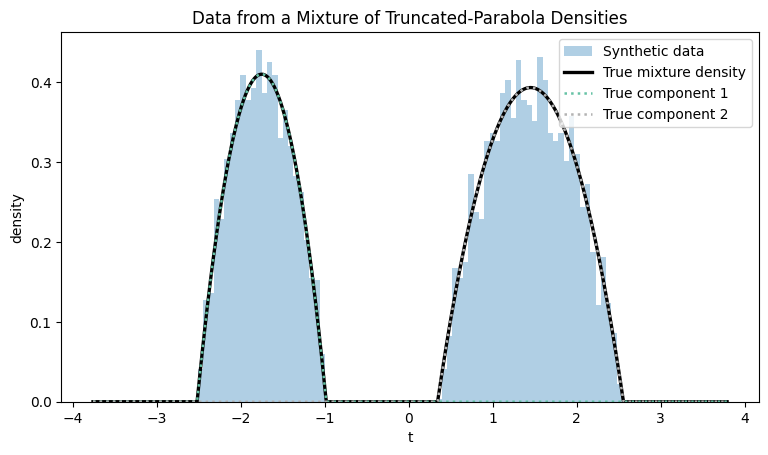

In [4]:
# Visualize histogram, true mixture density, and true component densities
grid_min = samples.min() - 1.25
grid_max = samples.max() + 1.25
grid = np.linspace(grid_min, grid_max, 1000)
f_true = mixture_density_truncated_parabola(grid, mu_true, sigma_true, pi_true)
component_colors = plt.cm.Set2(np.linspace(0, 1, K_true))

plt.figure(figsize=(9, 4.8))
plt.hist(samples, bins=80, density=True, alpha=0.35, color="tab:blue", label="Synthetic data")
plt.plot(grid, f_true, color="black", lw=2.4, label="True mixture density")
for k, color in enumerate(component_colors):
    fk = pi_true[k] * density_truncated_parabola(grid, mu_true[k], sigma_true[k])
    plt.plot(grid, fk, color=color, lw=1.8, ls=":", label=f"True component {k + 1}")
plt.title("Data from a Mixture of Truncated-Parabola Densities")
plt.xlabel("t")
plt.ylabel("density")
plt.legend()
plt.show()


In [5]:
def tau_from_sigma_torch(sigma):
    return -0.5 * torch.pow(3.0 / (2.0 * sigma), 2.0 / 3.0)


def component_densities_torch(t, mu, sigma):
    tau = tau_from_sigma_torch(sigma)
    quad = (t[:, None] - mu[None, :]) ** 2 / (2.0 * sigma[None, :] ** 2)
    return torch.relu(-tau[None, :] - quad)


def mixture_density_torch(t, mu, sigma, weight_logits):
    pi = torch.softmax(weight_logits, dim=0)
    components = component_densities_torch(t, mu, sigma)
    return components @ pi, components, pi


def batch_fy_mixture_loss(t, integration_grid, mu, sigma, weight_logits):
    p_samples, _, pi = mixture_density_torch(t, mu, sigma, weight_logits)
    p_grid, _, _ = mixture_density_torch(integration_grid, mu, sigma, weight_logits)

    # FY loss for scalar densities: 1/2 + 1/2 * ||p||_2^2 - E[p(X)]
    quadratic_term = 0.5 * torch.trapz(p_grid ** 2, integration_grid)
    data_term = p_samples.mean()
    loss = 0.5 + quadratic_term - data_term
    return loss, pi


In [6]:
# Gradient-based fitting of the mixture parameters

t = torch.tensor(samples, dtype=torch.float32)
integration_grid = torch.linspace(float(grid_min), float(grid_max), 2400, dtype=torch.float32)

K_fit = K_true
mu_init = np.quantile(samples, np.linspace(0.25, 0.75, K_fit))
mu = torch.nn.Parameter(torch.tensor(mu_init, dtype=torch.float32))
raw_sigma = torch.nn.Parameter(torch.full((K_fit,), -0.15, dtype=torch.float32))
weight_logits = torch.nn.Parameter(torch.zeros(K_fit, dtype=torch.float32))

optimizer = torch.optim.Adam([mu, raw_sigma, weight_logits], lr=0.04)

history = []
for step in range(2500):
    optimizer.zero_grad()
    sigma = torch.nn.functional.softplus(raw_sigma) + 1e-5
    loss, pi = batch_fy_mixture_loss(t, integration_grid, mu, sigma, weight_logits)
    loss.backward()
    optimizer.step()

    history.append(float(loss.detach().cpu().item()))
    if step % 400 == 0:
        print(
            f"step {step:4d} | loss={history[-1]:.6f} | "
            f"mu={mu.detach().cpu().numpy()} | "
            f"sigma={sigma.detach().cpu().numpy()} | "
            f"pi={pi.detach().cpu().numpy()}"
        )

with torch.no_grad():
    sigma_hat = (torch.nn.functional.softplus(raw_sigma) + 1e-5).detach().cpu().numpy()
    mu_hat = mu.detach().cpu().numpy()
    pi_hat = torch.softmax(weight_logits, dim=0).detach().cpu().numpy()

order_hat = np.argsort(mu_hat)
mu_hat = mu_hat[order_hat]
sigma_hat = sigma_hat[order_hat]
pi_hat = pi_hat[order_hat]

order_true = np.argsort(mu_true)
mu_true_sorted = mu_true[order_true]
sigma_true_sorted = sigma_true[order_true]
pi_true_sorted = pi_true[order_true]

print("Estimated parameters (sorted by mean)")
print("mu_hat    =", np.round(mu_hat, 5))
print("sigma_hat =", np.round(sigma_hat, 5))
print("pi_hat    =", np.round(pi_hat, 5))
print()
print("True parameters (sorted by mean)")
print("mu_true    =", np.round(mu_true_sorted, 5))
print("sigma_true =", np.round(sigma_true_sorted, 5))
print("pi_true    =", np.round(pi_true_sorted, 5))


step    0 | loss=0.351996 | mu=[-1.708484   1.5012795] | sigma=[0.6209671 0.6209671] | pi=[0.5 0.5]
step  400 | loss=0.340155 | mu=[-1.750726   1.4484234] | sigma=[0.5598233  0.94282705] | pi=[0.42740026 0.57259977]
step  800 | loss=0.340155 | mu=[-1.7507259  1.4484234] | sigma=[0.5598236 0.9428273] | pi=[0.42740017 0.5725999 ]
step 1200 | loss=0.340155 | mu=[-1.750726   1.4484234] | sigma=[0.559823  0.9428273] | pi=[0.42740017 0.5725998 ]
step 1600 | loss=0.340156 | mu=[-1.7507236  1.4484234] | sigma=[0.5592913 0.9428797] | pi=[0.42839605 0.57160395]
step 2000 | loss=0.340155 | mu=[-1.7507257  1.4484234] | sigma=[0.5598301 0.9428265] | pi=[0.42739135 0.57260865]
step 2400 | loss=0.340155 | mu=[-1.7507255  1.4484233] | sigma=[0.55961686 0.9428528 ] | pi=[0.42766806 0.57233196]
Estimated parameters (sorted by mean)
mu_hat    = [-1.75073  1.44842]
sigma_hat = [0.55982 0.94283]
pi_hat    = [0.4274 0.5726]

True parameters (sorted by mean)
mu_true    = [-1.75  1.45]
sigma_true = [0.55 0.95

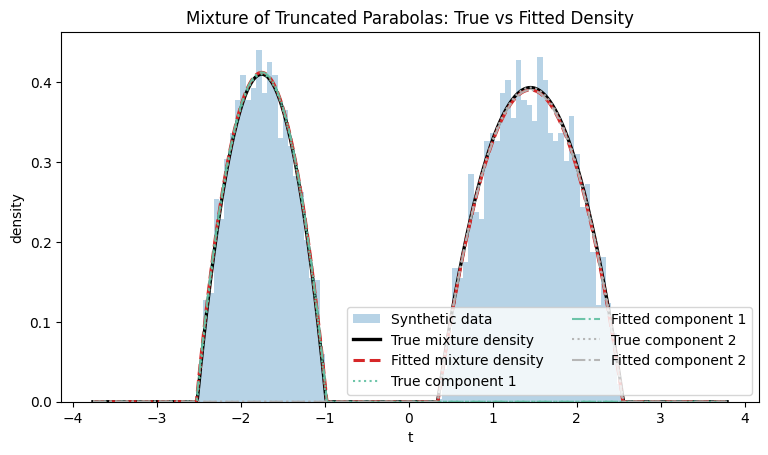

In [7]:
# Plot fitted mixture density against the true mixture
f_fit = mixture_density_truncated_parabola(grid, mu_hat, sigma_hat, pi_hat)

plt.figure(figsize=(9, 4.8))
plt.hist(samples, bins=80, density=True, alpha=0.32, color="tab:blue", label="Synthetic data")
plt.plot(grid, f_true, color="black", lw=2.4, label="True mixture density")
plt.plot(grid, f_fit, color="tab:red", lw=2.2, ls="--", label="Fitted mixture density")
for k, color in enumerate(component_colors):
    f_true_k = pi_true_sorted[k] * density_truncated_parabola(grid, mu_true_sorted[k], sigma_true_sorted[k])
    f_fit_k = pi_hat[k] * density_truncated_parabola(grid, mu_hat[k], sigma_hat[k])
    plt.plot(grid, f_true_k, color=color, lw=1.5, ls=":", alpha=0.95, label=f"True component {k + 1}")
    plt.plot(grid, f_fit_k, color=color, lw=1.5, ls="-.", alpha=0.95, label=f"Fitted component {k + 1}")
plt.title("Mixture of Truncated Parabolas: True vs Fitted Density")
plt.xlabel("t")
plt.ylabel("density")
plt.legend(ncol=2)
plt.show()


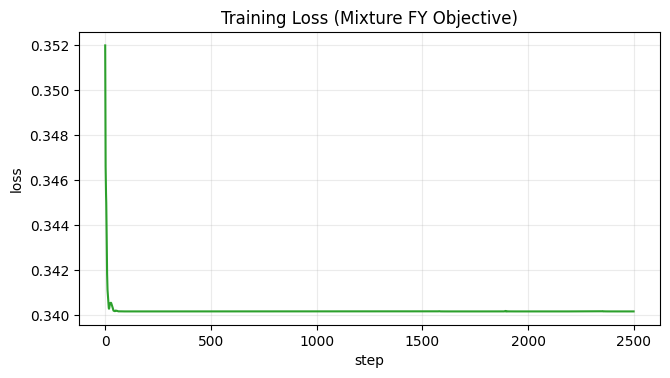

In [8]:
# Optimization trace
plt.figure(figsize=(7.5, 3.8))
plt.plot(history, color="tab:green")
plt.title("Training Loss (Mixture FY Objective)")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.25)
plt.show()
